In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D9/'

In [2]:
df_flat = pd.read_csv(main_dir + 'faiss_flat.csv')
df_flat['index'] = 'flat'
df_hnsw = pd.read_csv(main_dir + 'faiss_hnsw.csv')
df_hnsw['index'] = 'hnsw'
df_lsh = pd.read_csv(main_dir + 'faiss_lsh.csv')
df_lsh['index'] = 'lsh'

In [3]:
result = pd.DataFrame()
dfs = [df_flat, df_hnsw, df_lsh]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,61350,1,3.70,98.52,7.13,2270,59080,61488,34,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,122700,2,1.86,99.22,3.66,2286,120414,61504,18,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,184050,3,1.24,99.39,2.46,2290,181760,61508,14,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,245400,4,0.93,99.52,1.85,2293,243107,61511,11,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,306750,5,0.75,99.61,1.49,2295,304455,61513,9,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,368100,6,0.62,98.96,1.23,2280,365820,61498,24,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,429450,7,0.53,99.00,1.06,2281,427169,61499,23,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,490800,8,0.47,99.13,0.93,2284,488516,61502,20,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,552150,9,0.41,99.22,0.82,2286,549864,61504,18,lsh,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    960
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    960
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    960
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    960
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    960
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
17    30
18    30
19    30
20    30
21    30
22    30
23    30
24    30
25    30
26    30
27    30
28    30
29    30
30    30
31    30
32    30
Name: count, dtype: int64

In [10]:
valid_rows = result[result['Recall %']>=80]
valid_rows

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,61350,1,3.70,98.52,7.13,2270,59080,61488,34,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,122700,2,1.86,99.22,3.66,2286,120414,61504,18,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,184050,3,1.24,99.39,2.46,2290,181760,61508,14,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,245400,4,0.93,99.52,1.85,2293,243107,61511,11,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,306750,5,0.75,99.61,1.49,2295,304455,61513,9,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,368100,6,0.62,98.96,1.23,2280,365820,61498,24,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,429450,7,0.53,99.00,1.06,2281,427169,61499,23,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,490800,8,0.47,99.13,0.93,2284,488516,61502,20,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,552150,9,0.41,99.22,0.82,2286,549864,61504,18,lsh,[title],1024,0,32,salted_qgrams,,4


In [11]:
valid_rows['index'].value_counts()

index
flat    320
lsh     320
hnsw    283
Name: count, dtype: int64

In [12]:
max_f1 = valid_rows.loc[valid_rows.groupby(['num_hashes','index'])['F1 %'].idxmax()]
max_f1

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,61350,1,3.70,98.52,7.13,2270,59080,61488,34,flat,[title],1024,0,1,salted_qgrams,,4
320,FAISS HNSW Blocking,61350,1,3.24,86.28,6.25,1988,59362,61206,316,hnsw,[title],1024,0,1,salted_qgrams,,4
640,FAISS LSH Blocking,61350,1,3.70,98.52,7.13,2270,59080,61488,34,lsh,[title],1024,0,1,salted_qgrams,,4
10,FAISS FLAT Blocking,61350,1,3.70,98.48,7.13,2269,59081,61487,35,flat,[title],1024,0,2,salted_qgrams,,4
330,FAISS HNSW Blocking,61350,1,3.31,88.15,6.38,2031,59319,61249,273,hnsw,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
930,FAISS LSH Blocking,61350,1,3.68,98.09,7.10,2260,59090,61478,44,lsh,[title],1024,0,30,salted_qgrams,,4
300,FAISS FLAT Blocking,61350,1,3.68,98.00,7.09,2258,59092,61476,46,flat,[title],1024,0,31,salted_qgrams,,4
940,FAISS LSH Blocking,61350,1,3.68,98.00,7.09,2258,59092,61476,46,lsh,[title],1024,0,31,salted_qgrams,,4
310,FAISS FLAT Blocking,61350,1,3.68,97.87,7.09,2255,59095,61473,49,flat,[title],1024,0,32,salted_qgrams,,4


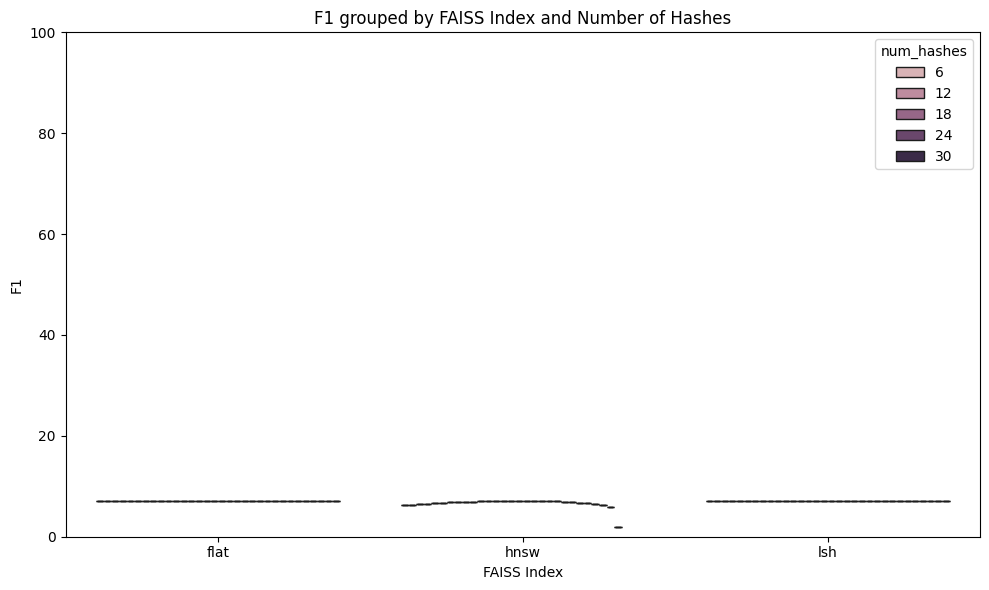

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="index",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by FAISS Index and Number of Hashes")
plt.xlabel("FAISS Index")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [14]:
metrics_df = max_f1.melt(
    id_vars=["index", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,index,num_hashes,Metric,Score
0,flat,1,Precision %,3.70
1,hnsw,1,Precision %,3.24
2,lsh,1,Precision %,3.70
3,flat,2,Precision %,3.70
4,hnsw,2,Precision %,3.31
...,...,...,...,...
274,lsh,30,F1 %,7.10
275,flat,31,F1 %,7.09
276,lsh,31,F1 %,7.09
277,flat,32,F1 %,7.09


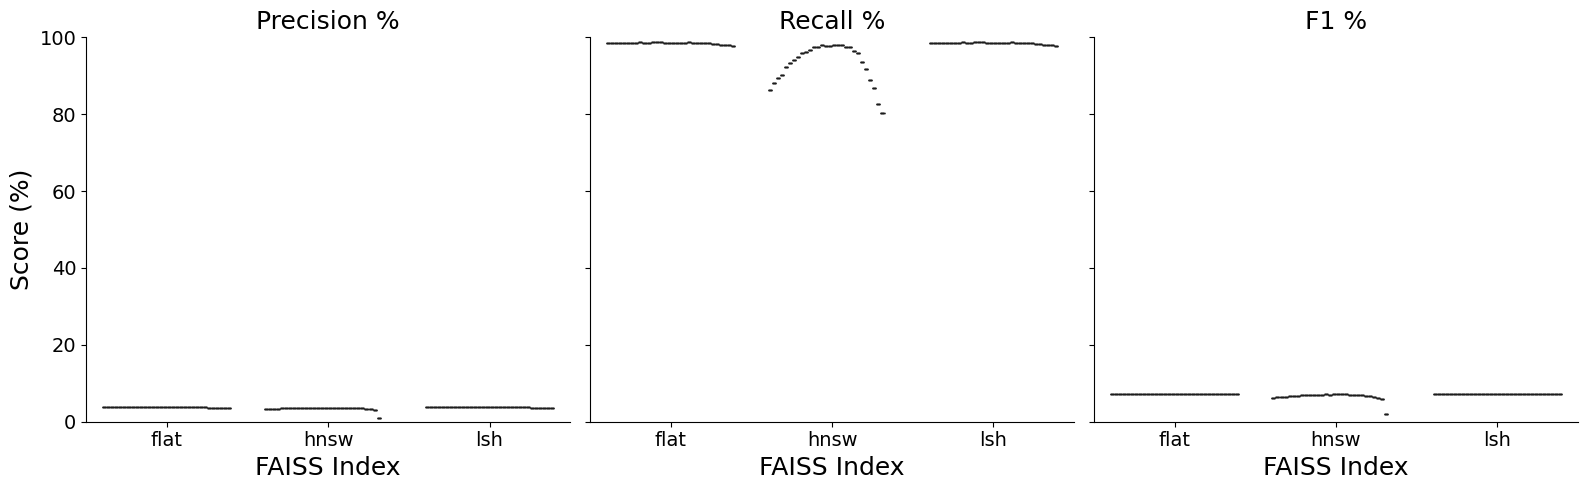

In [15]:
g = sns.catplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("FAISS Index", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

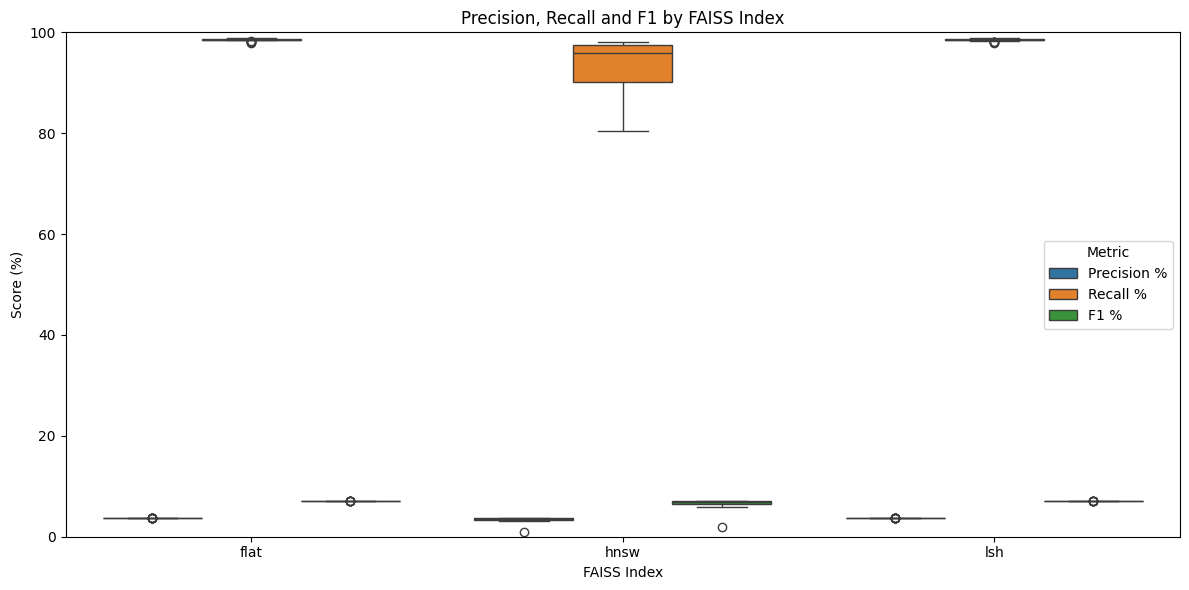

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by FAISS Index")
plt.xlabel("FAISS Index")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()